# LightGBM: nonlinear ML slice

**Question:** does a nonlinear model using all 10 features forecast next week's volatility better than HAR?

Everything above section 8 uses the **training years only**, scored with the shared 5-fold time-series CV. The test-run cells are locked behind `RUN_TEST = False` until the group's single test run (Wed 25 Nov), after the settings are frozen.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from lightgbm import LGBMRegressor

# Work from the repo root, like the main notebook (this notebook lives in slices/nonlinear_ml/)
if os.path.basename(os.getcwd()) == "nonlinear_ml":
    os.chdir("../..")
sys.path.append(os.getcwd())
from src.foundation.evaluate import evaluate, save_predictions

sns.set_theme(style="whitegrid", font_scale=1.1)
os.makedirs("results/figures", exist_ok=True)

RUN_TEST = False   # switch to True only on the test-run call, after FINAL_PARAMS is frozen
SEED = 42          # fixed seed, so every run gives the same model

In [2]:
# Load the shared model table (built by Main_Notebook.ipynb)
model_table = pd.read_csv("data/processed/model_table.csv", parse_dates=["date"])
train = model_table[model_table["split"] == "train"].reset_index(drop=True)
test = model_table[model_table["split"] == "test"].reset_index(drop=True)

FEATURES = ["f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8", "f9", "f10"]
X_train, y_train = train[FEATURES], train["y"]

# The same CV as every other model: 5 folds inside the training years, 5-row gap
tscv = TimeSeriesSplit(n_splits=5, gap=5)
print(f"Training rows: {len(train)} ({train['date'].min().date()} to {train['date'].max().date()})")

Training rows: 2452 (2005-03-30 to 2014-12-23)


## 1. Exploratory plot: last month's return vs next week's volatility

Feature 10 (SPY's return over the last 22 days) is one of the two features from this slice. The volume feature (f9) is plotted in the main notebook.

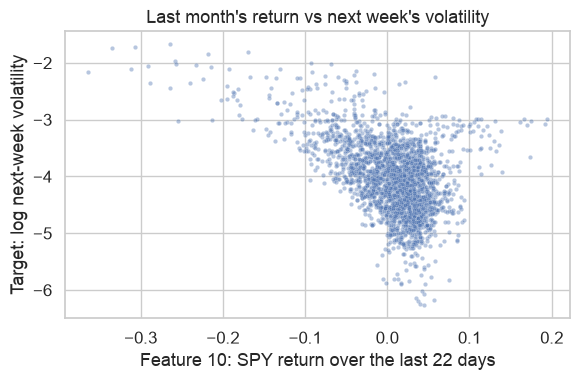

Correlation with the target: -0.475


In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(x=train["f10"], y=train["y"], s=10, alpha=0.4, ax=ax)
ax.set_xlabel("Feature 10: SPY return over the last 22 days")
ax.set_ylabel("Target: log next-week volatility")
ax.set_title("Last month's return vs next week's volatility")
plt.tight_layout()
plt.show()

print(f"Correlation with the target: {train['f10'].corr(train['y']):.3f}")

**Result.** The correlation is −0.48: after a month in which the market fell, next week tends to be more volatile. This is the leverage effect seen over a month rather than a day, and it is a clear, roughly linear pattern.

## 2. A helper to score a model on the 5 CV folds

For each fold the model is fitted on the earlier years and scored on the next block. We use the same function for every model below, so the comparison is fair.

In [4]:
def cv_scores(model, columns):
    """Fit on each fold's earlier years, score on the next block. One row per fold."""
    rows = []
    for fit_idx, val_idx in tscv.split(train):
        model.fit(train.loc[fit_idx, columns], y_train[fit_idx])
        y_pred = model.predict(train.loc[val_idx, columns])
        rows.append(evaluate(y_train[val_idx], y_pred))
    return pd.DataFrame(rows, index=range(1, 6)).rename_axis("fold")


def train_vs_cv_rmse(params):
    """Average RMSE on the fitted years vs on the scored block. A big gap means overfitting."""
    train_rmse, cv_rmse = [], []
    for fit_idx, val_idx in tscv.split(train):
        model = LGBMRegressor(random_state=SEED, verbose=-1, **params).fit(X_train.loc[fit_idx], y_train[fit_idx])
        train_rmse.append(evaluate(y_train[fit_idx], model.predict(X_train.loc[fit_idx]))["RMSE"])
        cv_rmse.append(evaluate(y_train[val_idx], model.predict(X_train.loc[val_idx]))["RMSE"])
    return np.mean(train_rmse), np.mean(cv_rmse)

## 3. First try: LightGBM with default settings

In [5]:
default_scores = cv_scores(LGBMRegressor(random_state=SEED, verbose=-1), FEATURES)
print("Mean over the 5 folds:", default_scores.mean().round(3).to_dict())
default_scores.round(3)

Mean over the 5 folds: {'MAE': 0.458, 'RMSE': 0.581, 'R2': -0.069}


,MAE,RMSE,R2
fold,,,
1,0.403,0.499,0.208
2,0.762,0.953,-1.235
3,0.414,0.532,0.238
4,0.365,0.482,0.258
5,0.346,0.440,0.187


In [6]:
train_rmse, cv_rmse = train_vs_cv_rmse({})
print(f"Default settings: RMSE on fitted years {train_rmse:.3f}, on the next block {cv_rmse:.3f}")

Default settings: RMSE on fitted years 0.127, on the next block 0.581


**Result.** With default settings the model fits the training years almost perfectly (RMSE 0.13) but does much worse on the next block (0.58), and in fold 2 it is far worse than predicting the average (R² −1.24). It is overfitting: the default trees (31 leaves, 100 trees) are too complex for about 2,400 rows.

## 4. Small grid search

We tune three settings, choosing by average CV RMSE:

- `num_leaves`: how complex each tree is;
- `learning_rate`: how much each new tree corrects the previous ones;
- `n_estimators`: how many trees.

Everything else stays at LightGBM's defaults.

In [7]:
param_grid = {"num_leaves": [7, 15, 31],
              "learning_rate": [0.01, 0.05],
              "n_estimators": [200, 500]}

grid = GridSearchCV(LGBMRegressor(random_state=SEED, verbose=-1), param_grid,
                    cv=tscv, scoring="neg_root_mean_squared_error")
grid.fit(X_train, y_train)

# scikit-learn reports negative RMSE; flip the sign so lower = better
results = pd.DataFrame(grid.cv_results_)
results["cv_rmse"] = -results["mean_test_score"]
print("Best settings:", grid.best_params_)
results[["param_num_leaves", "param_learning_rate", "param_n_estimators", "cv_rmse"]].sort_values("cv_rmse").round(3)

Best settings: {'learning_rate': 0.01, 'n_estimators': 200, 'num_leaves': 7}


,param_num_leaves,param_learning_rate,param_n_estimators,cv_rmse
0,7,0.01,200,0.529
3,7,0.01,500,0.535
1,15,0.01,200,0.542
4,15,0.01,500,0.551
2,31,0.01,200,0.552
6,7,0.05,200,0.554
5,31,0.01,500,0.562
7,15,0.05,200,0.575
9,7,0.05,500,0.579
8,31,0.05,200,0.583


The best settings are the most cautious ones in the grid (fewest leaves, slowest learning rate, fewest trees). When the best value sits at the edge of the grid, the true best might lie beyond it, so we tried even smaller values.

In [8]:
smaller_grid = {"num_leaves": [3, 7],
                "learning_rate": [0.005, 0.01],
                "n_estimators": [100, 200]}

grid_small = GridSearchCV(LGBMRegressor(random_state=SEED, verbose=-1), smaller_grid,
                          cv=tscv, scoring="neg_root_mean_squared_error")
grid_small.fit(X_train, y_train)
print("Best settings in the smaller grid:", grid_small.best_params_, f"CV RMSE {-grid_small.best_score_:.3f}")

Best settings in the smaller grid: {'learning_rate': 0.01, 'n_estimators': 200, 'num_leaves': 7} CV RMSE 0.529


In [9]:
train_rmse, cv_rmse = train_vs_cv_rmse(grid.best_params_)
print(f"Tuned settings: RMSE on fitted years {train_rmse:.3f}, on the next block {cv_rmse:.3f}")

Tuned settings: RMSE on fitted years 0.355, on the next block 0.529


**Result.** Going smaller does not help: the same settings win (7 leaves, learning rate 0.01, 200 trees, CV RMSE 0.529). The gap between the fitted years and the next block shrinks from 0.13 vs 0.58 to 0.36 vs 0.53, so the tuned model overfits much less.

## 5. Tuned LightGBM on each CV fold

In [10]:
tuned_scores = cv_scores(LGBMRegressor(random_state=SEED, verbose=-1, **grid.best_params_), FEATURES)
print("Mean over the 5 folds:", tuned_scores.mean().round(3).to_dict())
tuned_scores.round(3)

Mean over the 5 folds: {'MAE': 0.413, 'RMSE': 0.529, 'R2': 0.128}


,MAE,RMSE,R2
fold,,,
1,0.395,0.495,0.220
2,0.626,0.796,-0.561
3,0.375,0.496,0.339
4,0.335,0.439,0.383
5,0.333,0.419,0.260


**Result.** The tuned model scores CV RMSE 0.529 and R² 0.13 on average. It is positive in four folds (R² 0.22 to 0.38) but fails in fold 2, which covers the 2008 crisis (R² −0.56).

**Comparison with the other models.** CV RMSE on the same 5 folds (`TimeSeriesSplit(n_splits=5, gap=5)` on the training rows). Naive and HAR are from Tarannum's `slices/memory/memory_models.ipynb`, Elastic Net from Victor's `slices/linear_ml/elastic_net_model.ipynb`.

| Fold | Naive | HAR | Elastic Net | LightGBM |
|---|---|---|---|---|
| 1 | 0.621 | 0.531 | 0.451 | 0.495 |
| 2 (2008 crisis) | 0.480 | 0.487 | 0.430 | **0.796** |
| 3 | 0.569 | 0.505 | 0.461 | 0.496 |
| 4 | 0.607 | 0.494 | 0.434 | 0.439 |
| 5 | 0.552 | 0.521 | 0.408 | 0.419 |
| **Mean RMSE** | 0.566 | 0.508 | **0.437** | 0.529 |
| Mean R² | −0.03 | 0.18 | 0.41 | 0.13 |

- Elastic Net has the lowest RMSE in every fold.
- LightGBM beats HAR in 4 of the 5 folds. Its worse average comes from fold 2 alone: without fold 2, the mean RMSE is 0.462 for LightGBM and 0.513 for HAR.
- So LightGBM's problem is not the average week but the crisis weeks, which section 6 looks at.

## 6. Why does LightGBM fail in fold 2?

Fold 2 fits on Mar 2005 – Jun 2008 and scores on Jul 2008 – Feb 2010, which includes the crash. A tree predicts the average of the training days that fall in the same leaf, so it can never forecast a value beyond those it has seen.

In [11]:
fit_idx, val_idx = list(tscv.split(train))[1]          # fold 2
to_pct = lambda log_vol: np.exp(log_vol) * np.sqrt(252 / 5) * 100   # log 5-day volatility -> annualised %

fold2_model = LGBMRegressor(random_state=SEED, verbose=-1, **grid.best_params_).fit(X_train.loc[fit_idx], y_train[fit_idx])
pred_fold2 = fold2_model.predict(X_train.loc[val_idx])

print(f"Highest VIX in the fitted years: {np.exp(X_train.loc[fit_idx, 'f4'].max()):.1f}, in the scored block: {np.exp(X_train.loc[val_idx, 'f4'].max()):.1f}")
print(f"Highest volatility in the fitted years: {to_pct(y_train[fit_idx].max()):.0f}%, in the scored block: {to_pct(y_train[val_idx].max()):.0f}%")
print(f"Highest LightGBM forecast in the scored block: {to_pct(pred_fold2.max()):.0f}%")

Highest VIX in the fitted years: 32.2, in the scored block: 80.9
Highest volatility in the fitted years: 39%, in the scored block: 133%
Highest LightGBM forecast in the scored block: 21%


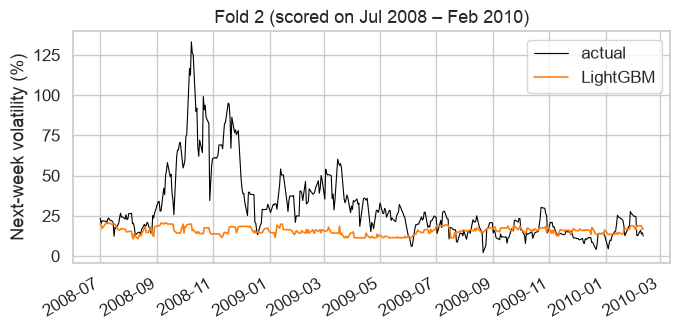

In [12]:
dates = train.loc[val_idx, "date"]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(dates, to_pct(y_train[val_idx]), color="black", lw=0.8, label="actual")
ax.plot(dates, to_pct(pred_fold2), color="tab:orange", lw=1.2, label="LightGBM")
ax.set_ylabel("Next-week volatility (%)")
ax.set_title("Fold 2 (scored on Jul 2008 – Feb 2010)")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("results/figures/lgbm_fold2_crisis.png", dpi=200)
plt.show()

**Result.** Before Jul 2008 the VIX never went above 32; in the scored block it reached 81, and next-week volatility peaked at 133%. LightGBM's highest forecast was only 21%: every crisis day lands in a leaf learned from much calmer days, so the forecast stays flat while volatility explodes. This is a known weakness of tree models: they cannot forecast beyond the range they were trained on.

**What we tried.** LightGBM has an option, `linear_tree=True`, that fits a small linear regression in each leaf instead of a constant, which in principle lets it extrapolate.

In [13]:
linear_tree_scores = cv_scores(LGBMRegressor(random_state=SEED, verbose=-1, linear_tree=True, **grid.best_params_), FEATURES)
print("Mean over the 5 folds:", linear_tree_scores.mean().round(3).to_dict())
linear_tree_scores.round(3)

Mean over the 5 folds: {'MAE': 0.454, 'RMSE': 0.609, 'R2': -0.302}


,MAE,RMSE,R2
fold,,,
1,0.349,0.444,0.372
2,0.890,1.259,-2.903
3,0.371,0.488,0.361
4,0.333,0.439,0.384
5,0.328,0.415,0.274


**Result.** It is worse, not better: average RMSE 0.609, and in fold 2 the R² falls to −2.9 because the linear leaves now overshoot. We keep ordinary trees.

**What this means for the test.** The final model is trained on all training years, including 2008, so it has seen a VIX of 81. The 2015–2017 test period is calmer, so the "can't go beyond what it has seen" problem should matter less there. How LightGBM compares with the other models on the test period is what the group's test run will tell us.

## 7. Final settings (frozen Wed 25 Nov)

Chosen by the lowest average CV RMSE in section 4. These do not change after this point.

In [14]:
FINAL_PARAMS = {"num_leaves": 7, "learning_rate": 0.01, "n_estimators": 200}
print("Same as the grid search's choice:", FINAL_PARAMS == grid.best_params_)

Same as the grid search's choice: True


## 8. Test run (only on the group call, Wed 25 Nov)

Train once on all training years with the frozen settings, forecast the test period, and save `results/preds_lgbm.csv`. Nothing above this cell may change after it has been run.

In [15]:
if RUN_TEST:
    # The test set is used once: stop if an earlier run already saved predictions
    # (check added after the 25 Nov test run, as in the other models' test cells)
    assert not os.path.exists("results/preds_lgbm.csv"), "preds_lgbm.csv exists: test set already used"
    final_model = LGBMRegressor(random_state=SEED, verbose=-1, **FINAL_PARAMS).fit(X_train, y_train)
    y_pred = final_model.predict(test[FEATURES])
    save_predictions("lgbm", test, y_pred)
    print("Saved results/preds_lgbm.csv")
    print("Test scores:", {k: round(float(v), 3) for k, v in evaluate(test["y"], y_pred).items()})
else:
    print("Locked: RUN_TEST is False")

Saved results/preds_lgbm.csv
Test scores: {'MAE': 0.411, 'RMSE': 0.53, 'R2': 0.271}


## 9. After the test run: what drives the model, and where it goes wrong

The SHAP summary shows which features push LightGBM's forecasts up or down. The second figure compares LightGBM with HAR over the test period and marks LightGBM's 5 biggest misses, measured in volatility points (%). It needs `results/preds_har.csv` from Tarannum's HAR model.

/private/tmp/claude-501/-Users-araf-Library-CloudStorage-GoogleDrive-sadmanaraf-gmail-com-My-Drive-DCU-Term-1-CSC1181--Stat-/eb31a932-b02e-425e-a4ae-62c01233f17d/scratchpad/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


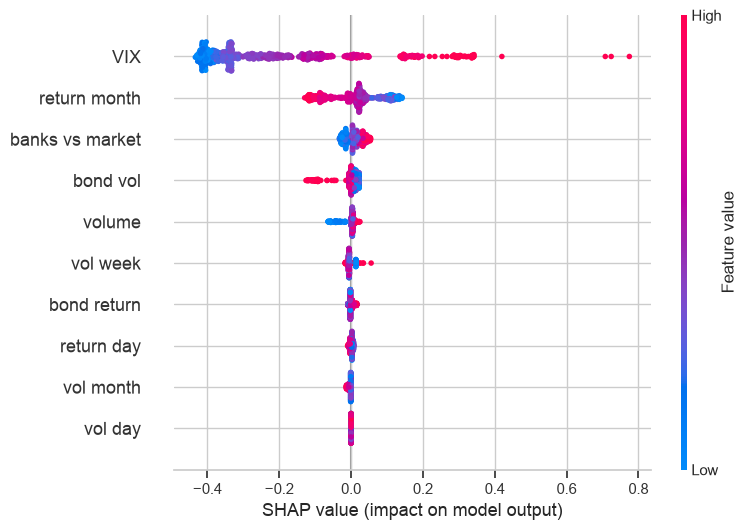

In [16]:
if RUN_TEST:
    import shap
    explainer = shap.TreeExplainer(final_model)
    shap_values = explainer.shap_values(test[FEATURES])
    names = {"f1": "vol day", "f2": "vol week", "f3": "vol month", "f4": "VIX", "f5": "return day",
             "f6": "bond vol", "f7": "banks vs market", "f8": "bond return", "f9": "volume", "f10": "return month"}
    shap.summary_plot(shap_values, test[FEATURES].rename(columns=names), show=False)
    plt.tight_layout()
    plt.savefig("results/figures/shap_lgbm.png", dpi=200)
    plt.show()
else:
    print("Locked: RUN_TEST is False")

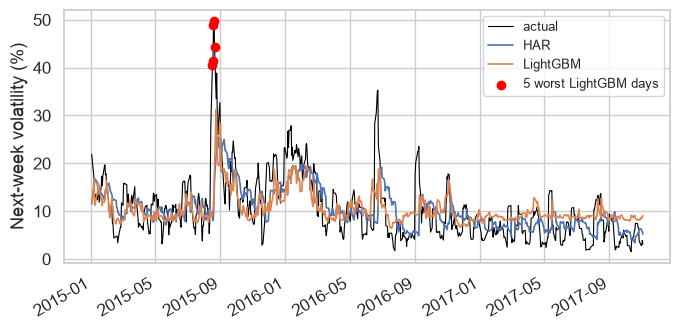

      date  actual %  LightGBM %
2015-08-19      48.9        11.7
2015-08-20      49.7        13.9
2015-08-17      40.5         9.1
2015-08-18      41.4        10.2
2015-08-21      44.4        19.5


In [17]:
if RUN_TEST and os.path.exists("results/preds_har.csv"):
    har = pd.read_csv("results/preds_har.csv", parse_dates=["date"])
    lgbm = pd.read_csv("results/preds_lgbm.csv", parse_dates=["date"])
    # 5 biggest misses in volatility points (%), so large crisis misses count more than tiny calm-day ones
    worst = (to_pct(lgbm["y_pred"]) - to_pct(lgbm["y_true"])).abs().nlargest(5).index

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(lgbm["date"], to_pct(lgbm["y_true"]), color="black", lw=0.8, label="actual")
    ax.plot(har["date"], to_pct(har["y_pred"]), lw=1.2, label="HAR")
    ax.plot(lgbm["date"], to_pct(lgbm["y_pred"]), lw=1.2, label="LightGBM")
    ax.scatter(lgbm.loc[worst, "date"], to_pct(lgbm.loc[worst, "y_true"]), color="red", zorder=3,
               label="5 worst LightGBM days")
    ax.set_ylabel("Next-week volatility (%)")
    ax.legend(fontsize=9)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.savefig("results/figures/predicted_vs_actual.png", dpi=200)
    plt.show()

    worst_days = lgbm.loc[worst, ["date"]].copy()
    worst_days["actual %"] = to_pct(lgbm.loc[worst, "y_true"]).round(1)
    worst_days["LightGBM %"] = to_pct(lgbm.loc[worst, "y_pred"]).round(1)
    print(worst_days.to_string(index=False))
else:
    print("Locked until the test run, and needs results/preds_har.csv")

### 9.1 Result of the test run

- **Test scores:** RMSE 0.530, MAE 0.411, R² 0.27 (section 8). The CV estimate was RMSE 0.529, so CV predicted the test error well.
- **Against the other models** (`results/metrics.csv`): Elastic Net 0.482, LightGBM 0.530, HAR 0.535, naive 0.621. LightGBM is slightly below HAR, but the Diebold–Mariano test (`results/dm_tests.csv`) gives a Holm p-value of 0.86: no significant difference. Elastic Net is the only model significantly better than HAR (p = 0.007).
- **Why LightGBM is closer to HAR than in CV:** the test years have no crisis like 2008. The highest next-week volatility in the test period is 50%, against 133% in the training years (section 6), so the fold-2 failure does not happen again.
- **What drives it (SHAP figure):** the VIX has by far the widest spread: a high VIX pushes the forecast up and a low VIX pushes it down. The SPY 22-day return comes next (after a fall, the forecast goes up). The three HAR features (vol day, week and month) are close to zero, so the model takes its information about volatility from the VIX instead. Elastic Net does the same: the lasso set f1–f3 to zero (Victor's section 9).
- **Biggest misses:** all five are forecasts made on 17–21 Aug 2015, i.e., one event, the sell-off of 24 Aug 2015. Actual volatility was 40–50% while LightGBM forecast 9–20%, and HAR also stayed low (figure above). On 17–19 Aug the VIX (13–15) and past-week volatility (5–8%) were still low; the VIX only started to rise on 20–21 Aug (section 10).
- **By period** (`integration/errors_by_period.ipynb`): LightGBM has a lower MAE than HAR in normal (0.346 vs 0.407) and stressed weeks (0.257 vs 0.327) but a higher one in calm weeks (0.488 vs 0.440), where it forecasts too high on average (mean error −0.286). Since 411 of the 717 test days are calm, this cancels its gains elsewhere.

## 10. After the test run: report-size figures and two checks

These cells only read the saved predictions (`results/preds_*.csv`) and the model table, so nothing is tuned on the test years. The SHAP cell refits the frozen model on the training rows and first checks that it gives exactly the saved test forecasts.

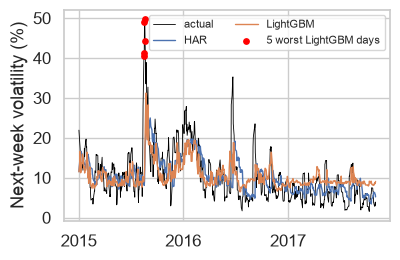

In [18]:
import matplotlib.dates as mdates

har = pd.read_csv("results/preds_har.csv", parse_dates=["date"])
lgbm = pd.read_csv("results/preds_lgbm.csv", parse_dates=["date"])
assert (lgbm["date"].values == test["date"].values).all() and (har["date"].values == test["date"].values).all()

# Predicted vs actual, drawn at report width (same content as section 9, larger text)
worst = (to_pct(lgbm["y_pred"]) - to_pct(lgbm["y_true"])).abs().nlargest(5).index
fig, ax = plt.subplots(figsize=(4.2, 2.8))
ax.plot(lgbm["date"], to_pct(lgbm["y_true"]), color="black", lw=0.6, label="actual")
ax.plot(har["date"], to_pct(har["y_pred"]), lw=1, label="HAR")
ax.plot(lgbm["date"], to_pct(lgbm["y_pred"]), lw=1, label="LightGBM")
ax.scatter(lgbm.loc[worst, "date"], to_pct(lgbm.loc[worst, "y_true"]), color="red", s=15, zorder=3,
           label="5 worst LightGBM days")
ax.set_ylabel("Next-week volatility (%)")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(fontsize=8, ncol=2, loc="upper right")
plt.tight_layout()
plt.savefig("results/figures/predicted_vs_actual.png", dpi=300)
plt.show()

/private/tmp/claude-501/-Users-araf-Library-CloudStorage-GoogleDrive-sadmanaraf-gmail-com-My-Drive-DCU-Term-1-CSC1181--Stat-/eb31a932-b02e-425e-a4ae-62c01233f17d/scratchpad/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


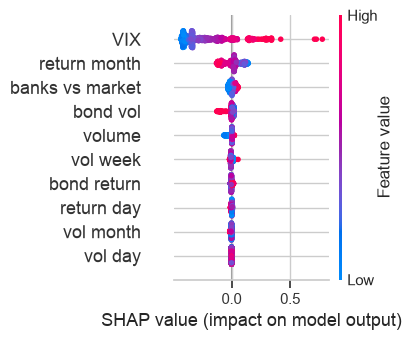

In [19]:
import shap

# Same frozen model as the test run: refit on the training rows and check the forecasts match exactly
report_model = LGBMRegressor(random_state=SEED, verbose=-1, **FINAL_PARAMS).fit(train[FEATURES], train["y"])
assert np.allclose(report_model.predict(test[FEATURES]), lgbm["y_pred"]), "not the test-run model"

shap_values = shap.TreeExplainer(report_model).shap_values(test[FEATURES])
names = {"f1": "vol day", "f2": "vol week", "f3": "vol month", "f4": "VIX", "f5": "return day",
         "f6": "bond vol", "f7": "banks vs market", "f8": "bond return", "f9": "volume", "f10": "return month"}
shap.summary_plot(shap_values, test[FEATURES].rename(columns=names), show=False, plot_size=(4.2, 3.6))
plt.tight_layout()
plt.savefig("results/figures/shap_lgbm.png", dpi=300)
plt.show()

In [20]:
# Check 1: the VIX and past volatility on the days of the five worst misses (17-21 Aug 2015)
aug = test[(test["date"] >= "2015-08-17") & (test["date"] <= "2015-08-21")]
print(pd.DataFrame({"date": aug["date"].dt.date, "VIX": np.exp(aug["f4"]).round(1),
                    "past-week vol %": to_pct(aug["f2"]).round(0), "next-week vol %": to_pct(aug["y"]).round(0)}).to_string(index=False))

# Check 2: did the VIX fall below anything seen in the training years?
vix_min_train = np.exp(train["f4"].min())
below = np.exp(test["f4"]) < vix_min_train
print(f"\nLowest VIX: training years {vix_min_train:.2f}, test years {np.exp(test['f4'].min()):.2f}")
print(f"Test days with the VIX below the training minimum: {below.sum()} (years: {sorted(test.loc[below, 'date'].dt.year.unique().tolist())})")
for name, p in [("LightGBM", lgbm), ("HAR", har)]:
    err = p["y_true"] - p["y_pred"]   # negative = forecast too high
    print(f"{name}: mean error {err[below].mean():.2f} on those days, {err[~below].mean():.2f} on the other days")
in_2017 = test["date"].dt.year == 2017
print(f"2017 average volatility: actual {to_pct(lgbm.loc[in_2017, 'y_true']).mean():.1f}%, "
      f"LightGBM {to_pct(lgbm.loc[in_2017, 'y_pred']).mean():.1f}%, HAR {to_pct(har.loc[in_2017, 'y_pred']).mean():.1f}%")

      date  VIX  past-week vol %  next-week vol %
2015-08-17 13.0              8.0             41.0
2015-08-18 13.8              5.0             41.0
2015-08-19 15.2              8.0             49.0
2015-08-20 19.1             17.0             50.0
2015-08-21 28.0             28.0             44.0

Lowest VIX: training years 9.89, test years 9.14
Test days with the VIX below the training minimum: 26 (years: [2017])
LightGBM: mean error -0.95 on those days, -0.13 on the other days
HAR: mean error -0.58 on those days, -0.09 on the other days
2017 average volatility: actual 6.1%, LightGBM 9.0%, HAR 6.8%


### 10.1 Result

- **Figures:** `predicted_vs_actual.png` and `shap_lgbm.png` are redrawn at report width with larger text; the refit model gives exactly the saved test forecasts, so the SHAP plot is of the test-run model.
- **August 2015:** on 17–19 Aug the VIX was 13.0–15.2 and past-week volatility 5–8%, while next-week volatility was 41–49%. The VIX only rose on 20–21 Aug (19.1 and 28.0). So the features gave little warning on most of those days, and both HAR and LightGBM stayed low.
- **Calm 2017:** the VIX fell to 9.14, below the training minimum of 9.89, on 26 test days, all in 2017. On those days LightGBM forecast too high by 0.95 on average (log scale) against 0.58 for HAR, and over 2017 it forecast 9.0% on average when actual volatility was 6.1% (HAR 6.8%). This is the same "can't go beyond the training range" weakness as in the 2008 fold (section 6), now at the low end, and it explains part of LightGBM's larger calm-period errors (`integration/errors_by_period.ipynb`).